<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/03_vision/notebooks/sesion_03_6_integrador_eurosat.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/03_vision/notebooks/sesion_03_6_integrador_eurosat.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F03_vision%2Fnotebooks%2Fsesion_03_6_integrador_eurosat.ipynb)

# SI7011 · Sesión 03 · Ejercicio integrador: ¿ImageNet sirve para mirar la Tierra desde el espacio?
**Juan David Martínez Vargas · Universidad EAFIT**

En los notebooks 1–5 cada pieza apareció sola: la CNN, BatchNorm, los residuales, la augmentation, el transfer learning. Aquí **las combinas** sobre datos nuevos y registras cada corrida en MLflow, como en el integrador de la sesión 02. Cada TODO indica en qué notebook está la pieza.

**Datos: EuroSAT.** 27 000 imágenes del satélite Sentinel-2, de 64×64 píxeles en RGB, etiquetadas con **10 usos del suelo**: cultivos, bosque, autopista, río, zona residencial, mar o lago, entre otros. Son fotos tomadas desde arriba: no se parecen a las de ImageNet (diapositiva *When transfer helps less*).

| Etapa | Qué haces | Artefacto |
|---|---|---|
| Datos | validar el contrato, partir sin fuga y elegir una augmentation que respete el dominio (**TODO 1**) | `data_card.json` |
| Entrenamiento | tu modelo (**TODO 2**) y tu optimizador (**TODO 3**); 3 corridas en MLflow | `best.pt` por corrida |
| Despliegue | predecir sobre imágenes crudas desde MLflow (**TODO 4**) | `predicciones.csv` |

**Duración:** 60–75 min. **Entorno:** Kaggle con GPU (agrega el dataset [`apollo2506/eurosat-dataset`](https://www.kaggle.com/datasets/apollo2506/eurosat-dataset) con **Add Input**) o Colab con GPU (lo descarga con tu secreto `KAGGLE_API_TOKEN`). En CPU usa `TRAIN_SIZE = 5_000`.

In [1]:
%pip install -q mlflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import copy, hashlib, json, math, os, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix

os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
import mlflow

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('PyTorch', torch.__version__, '· MLflow', mlflow.__version__, '· device', device)

PyTorch 2.15.0 · MLflow 3.18.0 · device mps


/Users/macbook/orca/workspaces/si7011-Martinez-Jimenez-Saldarriaga/Santiago/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Datos: contrato y ficha (listo)
El **contrato** dice qué acepta el modelo: imágenes RGB de 64×64 y una de las 10 clases. Se valida al cargar y se vuelve a validar al predecir. La **ficha** (*data card*) registra de dónde salieron los datos y se guarda con cada corrida.

In [3]:
KAGGLE_HANDLE = 'apollo2506/eurosat-dataset'
ROOTS = [Path('data'), Path('/kaggle/input'), Path('/teamspace/studios/this_studio/data')]

def kaggle_token():
    # Colab: secreto KAGGLE_API_TOKEN. Local o Lightning: variable de entorno o ~/.kaggle/access_token.
    if 'KAGGLE_API_TOKEN' not in os.environ:
        try:
            from google.colab import userdata
            os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN').strip()
        except Exception:
            pass
    return 'KAGGLE_API_TOKEN' in os.environ or (Path.home() / '.kaggle' / 'access_token').exists()

def find_rgb(roots):
    # El dataset trae EuroSAT/ (JPG, RGB) y EuroSATallBands/ (TIFF de 13 bandas): solo sirve la carpeta con JPG
    for root in [r for r in roots if r.exists()]:
        for d in sorted(root.rglob('AnnualCrop')):
            if d.is_dir() and next(d.glob('*.jpg'), None) is not None:
                return d.parent
    return None

def load_eurosat():
    folder = find_rgb(ROOTS)
    if folder is None and (kaggle_token() or Path('/kaggle/input').exists()):
        try:
            import kagglehub                               # preinstalado en Colab y Kaggle
            folder = find_rgb([Path(kagglehub.dataset_download(KAGGLE_HANDLE))])
        except Exception as e:
            print('kagglehub no disponible:', type(e).__name__, '→ se descarga con torchvision')
    if folder is not None:
        print('Leyendo', folder); return datasets.ImageFolder(folder), str(folder)
    print('EuroSAT no encontrado en disco: descargando con torchvision.datasets.EuroSAT')
    return datasets.EuroSAT('data', download=True), 'torchvision.datasets.EuroSAT'

ds, src = load_eurosat()
CLASSES = ds.classes; C = len(CLASSES)
CONTRACT = {'mode': 'RGB', 'size': [64, 64], 'classes': CLASSES}

# el mismo contrato se aplica al cargar los datos y al predecir (TODO 4)
def validate_image(img, contract=CONTRACT):
    if img.mode != contract['mode']:
        raise ValueError(f"Se esperaba una imagen {contract['mode']}, llegó {img.mode}.")
    if list(img.size) != contract['size']:
        raise ValueError(f"Se esperaba {contract['size']}, llegó {list(img.size)}.")
    return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)        # uint8, 3 × 64 × 64

t0 = time.time()
X_all = torch.stack([validate_image(ds[i][0]) for i in range(len(ds))])
y_all = torch.tensor([label for _, label in ds.samples])
names = sorted(Path(p).name for p, _ in ds.samples)
data_card = {'fuente': src, 'sha256_nombres': hashlib.sha256('\n'.join(names).encode()).hexdigest()[:16],
             'imagenes': len(ds), 'clases': dict(zip(CLASSES, np.bincount(y_all, minlength=C).tolist()))}
json.dump(data_card, open('data_card.json', 'w'), indent=1)
print(f'{len(X_all)} imágenes en {time.time() - t0:.0f} s'); data_card

EuroSAT no encontrado en disco: descargando con torchvision.datasets.EuroSAT


  0%|                                              | 0.00/94.3M [00:00<?, ?B/s]

  0%|                                      | 131k/94.3M [00:00<01:12, 1.30MB/s]

  0%|                                      | 295k/94.3M [00:00<01:06, 1.41MB/s]

  1%|▎                                     | 688k/94.3M [00:00<00:37, 2.52MB/s]

  2%|▋                                    | 1.64M/94.3M [00:00<00:17, 5.18MB/s]

... (18 outputs left out)

 95%|██████████████████████████████████▉  | 89.1M/94.3M [00:02<00:00, 43.2MB/s]

100%|█████████████████████████████████████| 94.3M/94.3M [00:02<00:00, 37.6MB/s]

27000 imágenes en 2 s


{'fuente': 'torchvision.datasets.EuroSAT',
 'sha256_nombres': '41025a8d575789c1',
 'imagenes': 27000,
 'clases': {'AnnualCrop': 3000,
  'Forest': 3000,
  'HerbaceousVegetation': 3000,
  'Highway': 2500,
  'Industrial': 2500,
  'Pasture': 2000,
  'PermanentCrop': 2500,
  'Residential': 3000,
  'River': 2500,
  'SeaLake': 3000}}

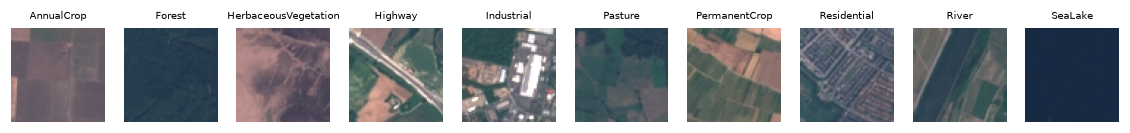

In [4]:
fig, axes = plt.subplots(1, C, figsize=(13, 1.8))
for c, ax in enumerate(axes):
    ax.imshow(X_all[(y_all == c).nonzero()[0, 0]].permute(1, 2, 0)); ax.set_title(CLASSES[c], fontsize=6.5); ax.axis('off')
plt.show()

Las clases están casi balanceadas, pero no del todo. Reportamos la accuracy y también el **F1 macro**, como en Covertype.

La normalización es la de ImageNet para todos los modelos, también para el que se entrena desde cero, y viaja dentro de cada `best.pt`.

In [5]:
MEAN = ResNet18_Weights.IMAGENET1K_V1.transforms().mean
STD = ResNet18_Weights.IMAGENET1K_V1.transforms().std
_m, _s = torch.tensor(MEAN, device=device).view(1, 3, 1, 1), torch.tensor(STD, device=device).view(1, 3, 1, 1)
prep = lambda xb: (xb.to(device).float() / 255 - _m) / _s   # (x/255 − μ)/s con μ, s de ImageNet (notebook 4)

## 2. TODO 1 · Partición y augmentation · 10 min
1. Haz una partición **estratificada** 70/15/15 de los índices (entrenamiento/validación/prueba) con `random_state=0`. Si `TRAIN_SIZE` no es `None`, toma una submuestra de ese tamaño del entrenamiento.
2. Escribe `augment(xb)`: recibe un lote normalizado $N \times 3 \times 64 \times 64$ y devuelve uno del mismo tamaño. Elige transformaciones que **no cambien la clase de una imagen satelital**. Piensa en el *Tu turno* 3 del notebook 3: lo que estaba mal en CIFAR-10, ¿está mal aquí?

No hay estadísticas que calcular con entrenamiento: la normalización es fija. La fuga que hay que evitar aquí es que una misma imagen quede en dos particiones.

In [6]:
TRAIN_SIZE = None            # en CPU: 5_000
idx_all = np.arange(len(y_all))

# TODO 1 ·
# (1) Partición estratificada 70/15/15 de los ÍNDICES con random_state=0, en dos etapas:
#     70 % entrenamiento / 30 % resto, y el resto a la mitad → 15 % validación y 15 % prueba.
#     Se parte una sola vez el conjunto de índices, así que cada imagen queda en exactamente una partición (sin fuga).
y_np = y_all.numpy()
idx_train, idx_rest = train_test_split(idx_all, test_size=0.30, stratify=y_np, random_state=0)
idx_val, idx_test = train_test_split(idx_rest, test_size=0.50, stratify=y_np[idx_rest], random_state=0)

#     Submuestra opcional, tomada SOLO del entrenamiento y estratificada (validación y prueba no cambian).
if TRAIN_SIZE is not None and TRAIN_SIZE < len(idx_train):
    idx_train, _ = train_test_split(idx_train, train_size=TRAIN_SIZE, stratify=y_np[idx_train], random_state=0)

# (2) augment(xb): las 8 simetrías del cuadrado (grupo diédrico D4), elegidas al azar para CADA imagen del lote:
#     una rotación de k·90° (k ∈ {0, 1, 2, 3}) seguida de un volteo horizontal con probabilidad 0.5
#     (el volteo vertical es volteo horizontal + rotación de 180°, así que ya está incluido).
#     Son permutaciones exactas de píxeles: no interpolan, no recortan, no dejan bordes negros y no tocan
#     los valores de color, así que funcionan igual sobre el lote ya normalizado por prep() (no se vuelve a normalizar).
#     Solo se usa en train_epoch; evaluate no la llama.
def augment(xb):
    n = xb.shape[0]
    k = torch.randint(0, 4, (n,), device=xb.device)                         # rotación por imagen
    flip = torch.rand(n, device=xb.device) < 0.5                             # volteo por imagen
    rots = torch.stack([torch.rot90(xb, r, dims=(2, 3)) for r in range(4)])  # 4 × N × 3 × 64 × 64
    out = rots[k, torch.arange(n, device=xb.device)]                         # N × 3 × 64 × 64
    out = torch.where(flip.view(-1, 1, 1, 1), out.flip(3), out)
    return out.contiguous()                                                  # mismo tamaño, dispositivo y dtype

print(f'entrenamiento {len(idx_train)} · validación {len(idx_val)} · prueba {len(idx_test)}')

entrenamiento 18900 · validación 4050 · prueba 4050


entrenamiento 18900 · validación 4050 · prueba 4050


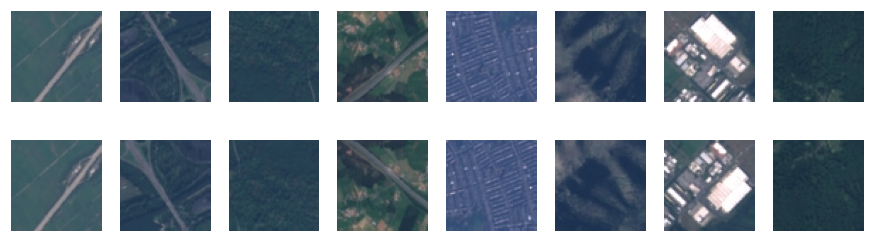

In [7]:
assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) and not (set(idx_val) & set(idx_test))
props = lambda idx: np.bincount(y_all[idx], minlength=C) / len(idx)
assert np.abs(props(idx_val) - props(idx_test)).max() < 0.01, 'Esperaba una partición estratificada.'
xb = prep(X_all[idx_train[:16]])
xa = augment(xb)
assert xa.shape == xb.shape, 'augment debe devolver un lote del mismo tamaño.'
assert not torch.allclose(xa, xb), 'augment no cambió nada.'
X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val, y_val = X_all[idx_val], y_all[idx_val]
X_test, y_test = X_all[idx_test], y_all[idx_test]
print('entrenamiento', len(y_train), '· validación', len(y_val), '· prueba', len(y_test))

show = lambda t: (t.cpu() * _s.cpu()[0] + _m.cpu()[0]).clamp(0, 1).permute(1, 2, 0)
fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for k in range(8):
    axes[0, k].imshow(show(xb[k])); axes[1, k].imshow(show(xa[k]))
for ax in axes.flat: ax.axis('off')
plt.show()

## 3. El loop y MLflow (listo)
`train_epoch` es el loop del notebook 3 con *scheduler* y la norma del gradiente. `run` hace lo mismo que en el integrador de la sesión 02:

- registra en **MLflow** los parámetros, las curvas por época, la pérdida inicial y la norma del gradiente;
- aplica **early stopping** sobre `val_loss`;
- guarda `best.pt` con los pesos **y** todo lo necesario para predecir: el nombre del constructor del modelo, la normalización y el contrato.

`before_epoch` permite, por ejemplo, congelar BatchNorm en cada época (notebook 4, sección 4).

In [8]:
loss_fn = nn.CrossEntropyLoss()  # L_i = −log softmax(f_θ(x_i))_{y_i}; recibe logits
BATCH = 128

def train_epoch(model, opt, scheduler=None, before_epoch=None):
    model.train()
    if before_epoch is not None:
        before_epoch(model)  # p. ej. freeze_bn (notebook 4, sección 4)
    perm = torch.randperm(len(y_train))
    total, norms = 0.0, []
    for i in range(0, len(perm), BATCH):
        b = perm[i:i + BATCH]
        # J_𝓑(θ) sobre el lote aumentado: tu augment del TODO 1, solo en entrenamiento (notebook 3, sección 3)
        loss = loss_fn(model(augment(prep(X_train[b]))), y_train[b].to(device))
        opt.zero_grad(); loss.backward()  # g_t = ∇_θ J_𝓑
        # ‖g_t‖ sin recortar (sesión 02, notebook 2, sección 6)
        norms.append(nn.utils.clip_grad_norm_(model.parameters(), float('inf')).item())
        opt.step()
        if scheduler is not None:
            scheduler.step()  # η_t = s(t) · η_0 en cada grupo (notebook 4, sección 4)
        total += loss.item() * len(b)
    return total / len(perm), float(np.mean(norms))

@torch.no_grad()
def evaluate(model, X, y, chunk=512):
    model.eval()  # Dropout apagado, BatchNorm con promedios móviles
    logits = torch.cat([model(prep(X[i:i + chunk])).float().cpu() for i in range(0, len(X), chunk)])
    pred = logits.argmax(1)
    return {'loss': loss_fn(logits, y).item(), 'acc': (pred == y).float().mean().item(),
            'macro_f1': f1_score(y, pred, average='macro', zero_division=0)}, pred.numpy()

In [9]:
mlflow.set_tracking_uri('sqlite:///mlflow.db')
EXPERIMENT = 'S03-eurosat'
mlflow.set_experiment(EXPERIMENT)

def run(name, build_model, make_opt, params, epochs=8, patience=3, before_epoch=None):
    torch.manual_seed(0)
    model = build_model().to(device)
    opt, scheduler = make_opt(model, epochs * math.ceil(len(y_train) / BATCH))
    with mlflow.start_run(run_name=name):
        mlflow.log_params({**params, 'epochs': epochs, 'patience': patience, 'train_size': len(y_train),
                           'n_params': sum(p.numel() for p in model.parameters()),
                           'n_trainable': sum(p.numel() for p in model.parameters() if p.requires_grad)})
        mlflow.log_dict(data_card, 'data_card.json')
        mlflow.log_metric('init_loss', evaluate(model, X_val, y_val)[0]['loss'])
        best, best_state, bad = {'val_loss': float('inf')}, None, 0
        for epoch in range(epochs):
            t0 = time.time()
            train_loss, grad_norm = train_epoch(model, opt, scheduler, before_epoch)
            va, _ = evaluate(model, X_val, y_val)
            row = {'train_loss': train_loss, 'grad_norm': grad_norm, 'lr': opt.param_groups[-1]['lr'],
                   'val_loss': va['loss'], 'val_acc': va['acc'], 'val_macro_f1': va['macro_f1'], 'epoch_s': time.time() - t0}
            if not math.isfinite(train_loss):
                mlflow.set_tag('status', 'diverged'); print('  diverge: se detiene'); break
            mlflow.log_metrics(row, step=epoch)
            # early stopping: θ* = argmin_t J_val(θ_t) (sesión 02, notebook 3, sección 4)
            if row['val_loss'] < best['val_loss']:
                best, best_state, bad = {**row, 'epoch': epoch}, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
            if bad == patience:
                mlflow.set_tag('early_stopped', epoch); break
        print(f"{name}: mejor época {best.get('epoch')} · val_loss {best['val_loss']:.4f} · "
              f"val_acc {best.get('val_acc', 0):.3f} · F1 macro {best.get('val_macro_f1', 0):.3f}")
        if best_state is not None:
            mlflow.log_metrics({'best_epoch': best['epoch'], 'best_val_loss': best['val_loss'],
                                'best_val_acc': best['val_acc'], 'best_val_macro_f1': best['val_macro_f1']})
            # best.pt lleva todo lo necesario para predecir: constructor, θ*, normalización y contrato
            torch.save({'model': build_model.__name__, 'state_dict': best_state, 'mean': MEAN, 'std': STD,
                        'contract': CONTRACT}, 'best.pt')
            mlflow.log_artifact('best.pt')
    return model

2026/11/23 00:06:12 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/23 00:06:12 INFO mlflow.store.db.utils: Updating database tables


2026/11/23 00:06:12 INFO mlflow.tracking.fluent: Experiment with name 'S03-eurosat' does not exist. Creating a new experiment.


## 4. Corrida 1 · Línea base: una CNN desde cero (lista)
La red con bloques VGG y BatchNorm del notebook 3, con 32, 64 y 128 canales para imágenes de 64×64, entrenada desde cero con Adam. Antes de correrla, **predice** su accuracy de validación.

_Mi predicción:_ EuroSAT tiene 10 clases casi balanceadas (azar = 10 %, $\ln 10 \approx 2.303$) con texturas y colores bien diferenciados en 64×64. Con 3 bloques VGG + BatchNorm, 18 900 imágenes de entrenamiento y augmentation $D_4$, en 8 épocas con Adam (`lr=1e-3`) espero una `val_acc` alrededor de **85 %–92 %**, muy por encima del azar aunque todavía con margen de mejora frente a un modelo residual preentrenado con schedule.

In [10]:
# bloques VGG con BatchNorm del notebook 3, secciones 1–2, para entradas de 64×64
def baseline_model():
    def block(c_in, c_out):
        return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(),
                             nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(),
                             nn.MaxPool2d(2))
    return nn.Sequential(block(3, 32), block(32, 64), block(64, 128), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, C))

def baseline_opt(model, total_steps):
    return torch.optim.Adam(model.parameters(), lr=1e-3), None

print(f'ln 10 = {math.log(C):.3f}')
run('1-cnn-desde-cero', baseline_model, baseline_opt, {'estrategia': 'desde cero', 'arquitectura': 'VGG-BN 32-64-128', 'optimizador': 'Adam', 'lr': 1e-3});

ln 10 = 2.303


1-cnn-desde-cero: mejor época 7 · val_loss 0.1972 · val_acc 0.936 · F1 macro 0.934


## 5. TODO 2 · Tu modelo · 15 min
Escribe `my_model()`. Debe devolver un modelo para imágenes de 3×64×64 y 10 salidas. Elige y **justifica** una estrategia del notebook 4:

- *linear probe*: ResNet-18 de ImageNet con el backbone congelado (`requires_grad = False`) y una cabeza nueva;
- *fine-tuning*: la misma red con todo entrenable;
- otra que puedas defender con evidencia.

Sigue la regla del notebook 4: los pesos con `ResNet18_Weights.IMAGENET1K_V1` y una capa `fc` nueva de `C` salidas. Las verificaciones de la celda siguiente son las del integrador de la sesión 02.

In [11]:
def my_model():
    # TODO 2 · Estrategia: fine-tuning completo de ResNet-18 preentrenada en ImageNet
    # 1. Backbone con los pesos de ImageNet (regla del notebook 4): sus filtros ya detectan bordes, texturas y
    #    patrones de color, un punto de partida mejor que pesos aleatorios.
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    # 2. Cabeza nueva: la fc original tiene 1000 salidas (clases de ImageNet); se reemplaza por una con C = 10
    #    salidas, una por uso del suelo, con las mismas 512 características de entrada.
    model.fc = nn.Linear(model.fc.in_features, C)
    # 3. Fine-tuning completo: TODO queda entrenable (backbone y cabeza), nada se congela. EuroSAT son fotos
    #    satelitales tomadas desde arriba, un dominio distinto de las fotos naturales de ImageNet, así que también
    #    se dejan adaptar las capas del backbone y no solo la cabeza.
    for p in model.parameters():
        p.requires_grad = True
    return model                                   # sin .to(device): las celdas siguientes lo hacen

**Justificación del TODO 2: fine-tuning completo.**

- **Qué aporta ImageNet:** las primeras capas de ResNet-18 aprendieron allí detectores genéricos de bordes, texturas y combinaciones de color. Son un punto de partida razonable también para imágenes satelitales.
- **Por qué no basta con un *linear probe*:** EuroSAT es un dominio distinto (diapositiva *When transfer helps less*). Son vistas cenitales de 64×64 a ≈10 m por píxel, sin objetos con orientación canónica, mientras que ImageNet son fotos naturales de objetos. Con el backbone congelado solo se entrenaría la cabeza sobre características pensadas para otro dominio. Con fine-tuning completo se adaptan tanto las características intermedias como las capas finales a texturas como cultivos, agua o tejido urbano.
- **La cabeza:** la `fc` nueva, de 512 → `C` = 10, produce un logit por clase de EuroSAT. Como arranca aleatoria, en el TODO 3 lleva un η mayor que el backbone.
- **Qué falta comprobar:** si ImageNet realmente ayuda frente a la CNN desde cero se verá al comparar las corridas `1-cnn-desde-cero` y `2-mi-receta` en MLflow (`best_val_acc` y `n_trainable`). Aquí no se afirma ningún resultado antes de correrlas.

In [12]:
torch.manual_seed(0)
m = my_model().to(device)
with torch.no_grad():
    m.eval(); init_loss = loss_fn(m(prep(X_val[:512])), y_val[:512].to(device)).item()
print(f'pérdida inicial {init_loss:.3f} (ln 10 = {math.log(C):.3f}) · entrenables {sum(p.numel() for p in m.parameters() if p.requires_grad):,}')
assert init_loss < 3 * math.log(C), 'La pérdida inicial está muy lejos de ln C: revisa la cabeza nueva.'

xb, yb = prep(X_train[:32]), y_train[:32].to(device)
opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=1e-3); m.train()
for _ in range(150):
    loss = loss_fn(m(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
print(f'sobreajustar 32 ejemplos: pérdida {loss.item():.4f}')
assert loss.item() < 0.1, 'El modelo no sobreajusta un lote: hay un error en el modelo.'

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/macbook/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


  0%|                                              | 0.00/44.7M [00:00<?, ?B/s]

  1%|▎                                     | 384k/44.7M [00:00<00:12, 3.64MB/s]

  5%|█▉                                   | 2.38M/44.7M [00:00<00:03, 13.4MB/s]

 17%|██████▏                              | 7.50M/44.7M [00:00<00:01, 26.5MB/s]

 30%|██████████▉                          | 13.2M/44.7M [00:00<00:00, 38.3MB/s]

... (4 outputs left out)

 95%|███████████████████████████████████  | 42.2M/44.7M [00:00<00:00, 54.9MB/s]

100%|█████████████████████████████████████| 44.7M/44.7M [00:01<00:00, 46.4MB/s]

pérdida inicial 2.762 (ln 10 = 2.303) · entrenables 11,181,642


sobreajustar 32 ejemplos: pérdida 0.0000


## 6. TODO 3 · Tu optimizador · 10 min
Escribe `my_opt(model, total_steps)` y que devuelva `(optimizador, scheduler)`:

- `torch.optim.AdamW` con **dos grupos de parámetros**: la cabeza `fc` con un $\eta$ mayor y el resto con uno menor (notebook 4, sección 4). Si tu modelo congela el backbone, el grupo del backbone queda vacío o sus parámetros no se mueven, y está bien;
- *warmup* lineal de **1 época** y decaimiento coseno (`warmup_cosine` del notebook 4). Hay `math.ceil(len(y_train) / BATCH)` pasos por época.

Después, en la celda de la corrida, escribe en `params` lo que elegiste y decide si usas `before_epoch=freeze_bn`.

In [13]:
def freeze_bn(model):
    for mod in model.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.eval()

def my_opt(model, total_steps):
    # TODO 3 · AdamW con dos grupos (backbone con η menor, cabeza fc al final con η mayor) + warmup lineal 1 época y coseno
    backbone = [p for n, p in model.named_parameters() if not n.startswith('fc.')]
    head = list(model.fc.parameters())
    opt = torch.optim.AdamW(
        [{'params': backbone, 'lr': 1e-4}, {'params': head, 'lr': 1e-3}],
        weight_decay=0.05,
    )
    warmup_steps = math.ceil(len(y_train) / BATCH)

    def warmup_cosine(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(opt, warmup_cosine)
    return opt, scheduler

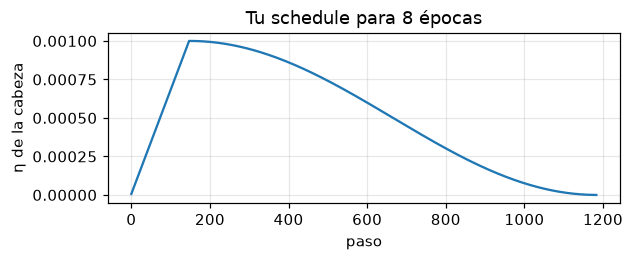

In [14]:
steps_per_epoch = math.ceil(len(y_train) / BATCH)
_m_ = my_model()
_opt, _sched = my_opt(_m_, 8 * steps_per_epoch)
assert isinstance(_opt, torch.optim.AdamW) and len(_opt.param_groups) == 2, 'Esperaba AdamW con dos grupos.'
lr_fc = [g['lr'] for g in _opt.param_groups if any(p is _m_.fc.weight for p in g['params'])]
lr_rest = [g['lr'] for g in _opt.param_groups if not any(p is _m_.fc.weight for p in g['params'])]
assert lr_fc and lr_rest and lr_fc[0] > lr_rest[0], 'La cabeza debe tener un η mayor que el backbone.'
lrs = []
for _ in range(8 * steps_per_epoch):
    lrs.append(_opt.param_groups[-1]['lr']); _opt.step(); _sched.step()
peak = int(np.argmax(lrs))
assert lrs[0] <= 1.5 * max(lrs) / steps_per_epoch and abs(peak - steps_per_epoch) <= 2, 'Esperaba warmup lineal durante la primera época.'
assert lrs[-1] < 0.01 * max(lrs), 'Esperaba que η llegara casi a cero al final.'
plt.figure(figsize=(6, 2)); plt.plot(lrs); plt.xlabel('paso'); plt.ylabel('η de la cabeza'); plt.title('Tu schedule para 8 épocas'); plt.show()

In [15]:
params = {
    'estrategia': 'fine-tuning completo',
    'arquitectura': 'resnet18 ImageNet',
    'optimizador': 'AdamW',
    'lr_backbone': 1e-4,
    'lr_cabeza': 1e-3,
    'weight_decay': 0.05,
    'schedule': 'warmup 1 época + coseno',
    'augment': 'D4 (rot90 + flip horizontal)',
    'freeze_bn': True,
}
run('2-mi-receta', my_model, my_opt, params, before_epoch=freeze_bn);

2-mi-receta: mejor época 7 · val_loss 0.0738 · val_acc 0.977 · F1 macro 0.975


## 7. Corrida 3 · Cambia una sola cosa · 5 min
Elige **un** cambio a tu receta y córrelo. Si escribes una función de modelo nueva, haz que su nombre termine en `_model` para que el despliegue la encuentre. Algunas opciones: la otra estrategia (probe o fine-tuning), sin augmentation, sin `freeze_bn`, `TRAIN_SIZE = 500`, o subir la imagen a 128×128 dentro del modelo con `nn.Upsample`. Antes de correrlo, escribe en `params` qué esperas que pase.

_Mi cambio y mi predicción:_ **Cambio único:** congelar el backbone de ResNet-18 (`probe_model()`, dejando entrenable únicamente la cabeza lineal `fc` con `5 130` parámetros frente a `11 181 642`), manteniendo idénticos `my_opt`, `augment` ($D_4$), `epochs=8`, `patience=3` y `before_epoch=freeze_bn`. **Predicción:** como EuroSAT consta de imágenes satelitales cenitales de 64×64 (dominio distinto a las fotos naturales de ImageNet, diapositiva *When transfer helps less*), congelar el backbone impondrá un techo claro: la corrida entrenará rápido y sin sobreajuste, pero quedará notablemente por debajo de `2-mi-receta` (y probablemente también por debajo de `1-cnn-desde-cero`), confirmando empíricamente la justificación del TODO 2.

In [16]:
def probe_model():
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    for p in model.parameters():
        p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, C)
    return model

params_probe = {
    **params,
    'estrategia': 'linear probe (backbone congelado)',
    'cambio': 'Congelar el backbone de ResNet-18 (solo fc entrenable: 5 130 vs 11 181 642 parámetros)',
    'prediccion': 'Techo claro por cambio de dominio (When transfer helps less): val_acc y F1 macro mucho menores que 2-mi-receta y probablemente inferiores a 1-cnn-desde-cero.',
}
run('3-linear-probe', probe_model, my_opt, params_probe, before_epoch=freeze_bn);

3-linear-probe: mejor época 7 · val_loss 0.2651 · val_acc 0.912 · F1 macro 0.908


## 8. Comparar en MLflow (listo)

In [17]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=['attributes.start_time ASC'])
runs = runs.drop_duplicates('tags.mlflow.runName', keep='last').set_index('tags.mlflow.runName')
cols = ['params.n_trainable', 'metrics.init_loss', 'metrics.best_epoch', 'metrics.best_val_loss', 'metrics.best_val_acc', 'metrics.best_val_macro_f1']
runs[cols].round(3)

,params.n_trainable,metrics.init_loss,metrics.best_epoch,metrics.best_val_loss,metrics.best_val_acc,metrics.best_val_macro_f1
tags.mlflow.runName,,,,,,
1-cnn-desde-cero,288746,2.304,7.0,0.197,0.936,0.934
2-mi-receta,11181642,2.716,7.0,0.074,0.977,0.975
3-linear-probe,5130,2.716,7.0,0.265,0.912,0.908


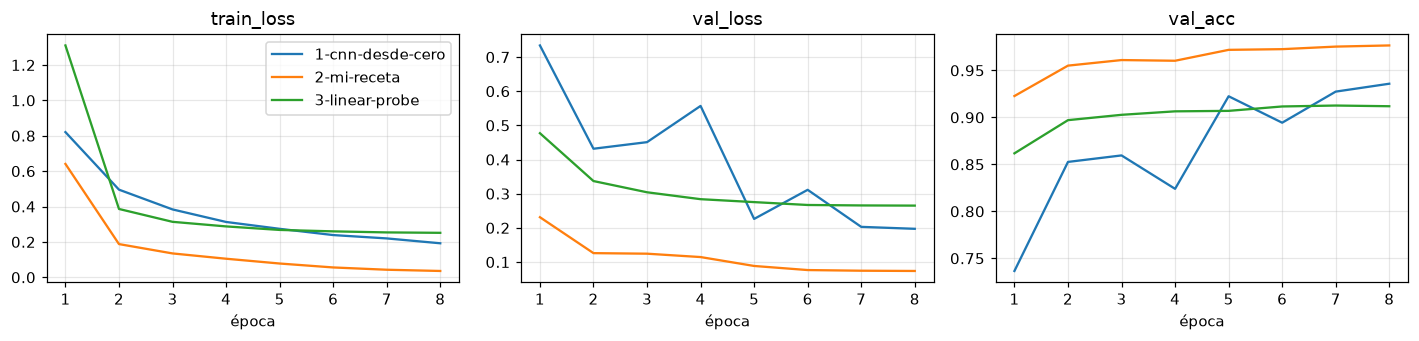

In [18]:
client = mlflow.MlflowClient()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for name, r in runs.iterrows():
    for ax, key in zip(axes, ['train_loss', 'val_loss', 'val_acc']):
        hist = client.get_metric_history(r.run_id, key)
        ax.plot([m.step + 1 for m in hist], [m.value for m in hist], label=name)
for ax, key in zip(axes, ['train_loss', 'val_loss', 'val_acc']):
    ax.set(title=key, xlabel='época')
axes[0].legend(); fig.tight_layout(); plt.show()

**Opcional · interfaz web.** En local, ejecuta `mlflow ui --backend-store-uri sqlite:///mlflow.db` y abre http://127.0.0.1:5000. En Kaggle o Colab, descarga `mlflow.db` y `mlruns/` y abre la interfaz en tu máquina.

## 9. Evaluar en prueba una sola vez (listo)
Se elige la corrida por `best_val_loss`, **nunca** por la prueba, y se carga su `best.pt` **desde MLflow**.

In [19]:
chosen = runs.sort_values('metrics.best_val_loss').iloc[0]
print('Corrida elegida:', chosen.name)
ckpt = torch.load(mlflow.artifacts.download_artifacts(run_id=chosen.run_id, artifact_path='best.pt'), map_location='cpu', weights_only=False)
BUILDERS = {f.__name__: f for f in [baseline_model, my_model] + [v for v in globals().values() if callable(v) and getattr(v, '__name__', '').endswith('_model')]}
model = BUILDERS[ckpt['model']](); model.load_state_dict(ckpt['state_dict']); model.to(device).eval()
test_metrics, pred_test = evaluate(model, X_test, y_test)
with mlflow.start_run(run_id=chosen.run_id):
    mlflow.log_metrics({f'test_{k}': v for k, v in test_metrics.items()})
print({k: round(v, 4) for k, v in test_metrics.items()})

Corrida elegida: 2-mi-receta


{'loss': 0.082, 'acc': 0.9704, 'macro_f1': 0.9691}


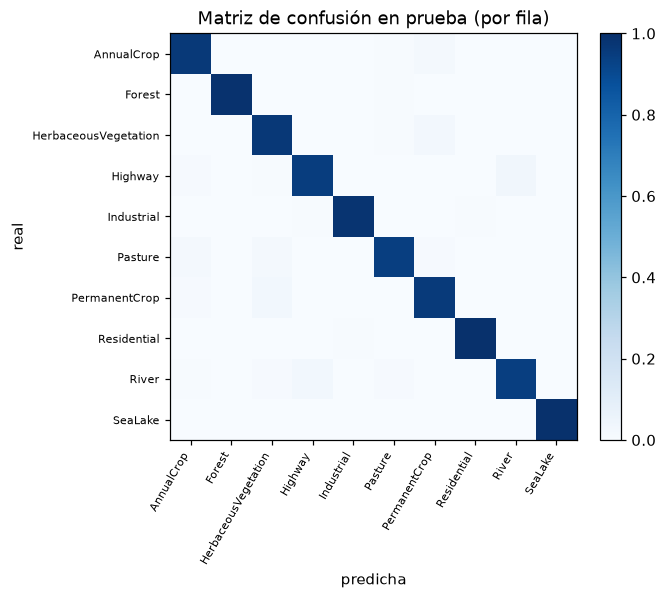

In [20]:
cm = confusion_matrix(y_test, pred_test, normalize='true')
plt.figure(figsize=(5.5, 4.8)); plt.imshow(cm, cmap='Blues', vmin=0, vmax=1); plt.colorbar(fraction=0.046)
plt.xticks(range(C), CLASSES, rotation=60, ha='right', fontsize=7); plt.yticks(range(C), CLASSES, fontsize=7)
plt.xlabel('predicha'); plt.ylabel('real'); plt.title('Matriz de confusión en prueba (por fila)'); plt.grid(False); plt.show()

## 10. TODO 4 · Despliegue: predecir sobre imágenes crudas · 10 min
Escribe `predict_raw(ckpt, images)`. Recibe una **lista de imágenes PIL**, como las que llegarían de un usuario, y devuelve un `DataFrame` con `clase` (el nombre) y `confianza`. Usa solo lo que trae `ckpt`:

1. `validate_image(img, ckpt['contract'])` para cada imagen, y apilar;
2. normalizar con `ckpt['mean']` y `ckpt['std']`;
3. reconstruir el modelo con `BUILDERS[ckpt['model']]()`, cargar los pesos y ponerlo en `eval()`;
4. aplicar softmax y elegir la clase.

In [21]:
@torch.no_grad()
def predict_raw(ckpt, images):
    # TODO 4 · inferencia autocontenida usando exclusivamente lo guardado en ckpt
    X = torch.stack([validate_image(img, ckpt['contract']) for img in images])
    mean = torch.tensor(ckpt['mean'], device=device).view(1, 3, 1, 1)
    std = torch.tensor(ckpt['std'], device=device).view(1, 3, 1, 1)
    model = BUILDERS[ckpt['model']]()
    model.load_state_dict(ckpt['state_dict'])
    model.to(device).eval()

    classes = ckpt['contract']['classes']
    probs_list = []
    chunk = 512
    for i in range(0, len(X), chunk):
        xb = (X[i:i + chunk].to(device).float() / 255.0 - mean) / std
        probs_list.append(F.softmax(model(xb).float(), dim=1).cpu())
    probs = torch.cat(probs_list, dim=0)
    conf, pred = probs.max(dim=1)
    return pd.DataFrame({
        'clase': [classes[i] for i in pred.tolist()],
        'confianza': conf.tolist(),
    })

In [22]:
to_pil = transforms.ToPILImage()
raw_test = [to_pil(x) for x in X_test]                          # imágenes crudas de prueba, como PIL

out = predict_raw(ckpt, raw_test)
agree = (out['clase'].map(CLASSES.index).to_numpy() == pred_test).mean()
print(f'1. Consistencia con la evaluación de prueba: {agree:.2%}')
assert agree > 0.999, 'El artefacto no reproduce las predicciones: ¿falta eval() o la normalización?'

for bad in [raw_test[0].convert('L'), raw_test[0].resize((32, 32))]:
    try:
        predict_raw(ckpt, [bad]); raise AssertionError('Una imagen inválida debió ser rechazada.')
    except ValueError as e:
        print('2. Contrato: imagen rechazada →', e)

pd.concat([pd.DataFrame({'real': [CLASSES[i] for i in y_test[:1000]]}), out.head(1000)], axis=1).to_csv('predicciones.csv', index=False)
print('3. predicciones.csv escrito'); out.head()

1. Consistencia con la evaluación de prueba: 100.00%
2. Contrato: imagen rechazada → Se esperaba una imagen RGB, llegó L.
2. Contrato: imagen rechazada → Se esperaba [64, 64], llegó [32, 32].
3. predicciones.csv escrito


,clase,confianza
0,Pasture,0.999912
1,Residential,0.999997
2,AnnualCrop,0.999996
3,HerbaceousVegetation,0.979920
4,HerbaceousVegetation,0.998070


## 11. Preguntas y entrega
1. ¿Se cumplió tu predicción para la línea base? ¿Qué número del registro de MLflow lo muestra?
2. ¿Ayudó ImageNet con imágenes satelitales? Compara la línea base con tu receta en `best_val_acc` **y** en `n_trainable`.
3. ¿Qué transformaciones pusiste en `augment` y por qué no cambian la clase en EuroSAT? ¿Cuál de ellas estaría mal en CIFAR-10?
4. Mira la matriz de confusión: ¿qué pares de clases se confunden más? ¿Te parece razonable viendo las imágenes?
5. ¿Qué pasaría en producción si alguien enviara imágenes de 128×128 de otro satélite? ¿Qué hace hoy `predict_raw` y qué debería hacer?

_Respuestas:_

1. **Predicción de la línea base:** antes de entrenar predijimos una `val_acc` entre **85 % y 92 %** para `1-cnn-desde-cero`. En MLflow, la corrida `1-cnn-desde-cero` alcanzó **`best_val_acc = 0.9358` (93.58 %)** en la época 7 (`best_val_loss = 0.1972`, `best_val_macro_f1 = 0.9337`, partiendo de `init_loss = 2.3039 ≈ ln 10 = 2.303`). El resultado superó ligeramente el extremo superior de nuestra predicción (+1.6 pp sobre 92 %), confirmando que con 18 900 ejemplos y augmentation $D_4$ una CNN compacta VGG+BN desde cero ya aprende bien las texturas de Sentinel-2.

2. **¿Ayudó ImageNet en imágenes satelitales?** **Sí, pero únicamente cuando se adapta todo el backbone (*fine-tuning completo*):**
   - `1-cnn-desde-cero`: `best_val_acc = 0.9358`, `best_val_loss = 0.1972`, `best_val_macro_f1 = 0.9337`, con **`n_trainable = 288 746`**.
   - `2-mi-receta` (fine-tuning completo de ResNet-18 preentrenada en ImageNet, `AdamW` con `lr_backbone = 1e-4`, `lr_cabeza = 1e-3`, `weight_decay = 0.05`, warmup 1 época + coseno y `freeze_bn=True`): **`best_val_acc = 0.9765`** (+4.07 pp frente a la línea base, reduciendo el error de validación de 6.42 % a 2.35 %), `best_val_loss = 0.0738`, `best_val_macro_f1 = 0.9753`, y en la evaluación única en prueba **`test_acc = 0.9704`**, `test_loss = 0.0820`, `test_macro_f1 = 0.9691`, a costa de **`n_trainable = 11 181 642`** (~38.7× más parámetros entrenables que la CNN desde cero).
   - `3-linear-probe` (mismo ResNet-18 de ImageNet pero con backbone congelado, **`n_trainable = 5 130`**): baja a **`best_val_acc = 0.9119`**, `best_val_loss = 0.2651` y `best_val_macro_f1 = 0.9083` —2.40 pp **por debajo** de la CNN desde cero. Esto respalda *When transfer helps less*: las características congeladas de ImageNet tienen techo en imágenes cenitales satelitales, pero son una inicialización muy superior si se ajustan todas las capas.

3. **Transformaciones en `augment` ($D_4$) vs. CIFAR-10:** se implementaron las **8 simetrías del cuadrado (grupo diédrico $D_4$)** por imagen: rotaciones exactas de $k \cdot 90^\circ$ ($k \in \{0, 1, 2, 3\}$) seguidas de volteo horizontal con probabilidad $0.5$ (lo que, combinado con $180^\circ$, incluye también el volteo vertical). En EuroSAT no cambian la clase porque son vistas cenitales (nadir) sin eje gravitacional ni orientación canónica: un cultivo, bosque, río o autopista rotado o reflejado sigue representando el mismo uso del suelo, y además son permutaciones exactas de píxeles sin interpolación ni bordes negros. En **CIFAR-10 estarían mal las rotaciones de $90^\circ$, $180^\circ$ y $270^\circ$ y el volteo vertical**, porque las fotos naturales sí tienen gravedad y orientación canónica (cielo arriba, suelo abajo; un auto, avión o animal invertido sale de la distribución real, donde solo el volteo horizontal es válido).

4. **Pares más confundidos en la matriz de confusión de prueba (`2-mi-receta`, 4 050 imágenes):** *(la celda 33 grafica la matriz normalizada sin anotaciones numéricas; los conteos y porcentajes exactos citados provienen de inspeccionar aparte `confusion_matrix(y_test, pred_test)` sin normalizar sobre las predicciones de prueba `pred_test` de la celda 32)*.
   - **`Highway` ↔ `River`** (23 errores totales): `Highway → River` **3.20 %** (12/375) y `River → Highway` **2.93 %** (11/375).
   - **`PermanentCrop` ↔ `HerbaceousVegetation`** (22 errores totales): `PermanentCrop → HerbaceousVegetation` **2.93 %** (11/375) y `HerbaceousVegetation → PermanentCrop` **2.44 %** (11/450).
   - En menor medida, confusiones entre coberturas agrícolas y herbáceas: **`AnnualCrop` ↔ `PermanentCrop`** (12 errores; `AnnualCrop → PermanentCrop` 2.00 % [9/450]), **`Pasture` → `HerbaceousVegetation`** (2.33 % [7/300]) y **`Pasture` → `AnnualCrop`** (2.00 % [6/300]). En contraste, clases visualmente bien definidas como `Residential` (99.56 %), `SeaLake` (99.33 %), `Forest` (99.11 %) e `Industrial` (98.40 %) alcanzan recalls cercanos al 100 %.
   - **Razonabilidad visual:** sí es muy razonable. A 64×64 (≈10 m/píxel), tanto autopistas como ríos aparecen como franjas delgadas y oscuras que cruzan terreno abierto; y usando solo bandas RGB es difícil separar cultivos permanentes, anuales, pasturas y vegetación herbácea sin bandas infrarrojas (NIR/SWIR) o información multitemporal.

5. **Imágenes de 128×128 de otro satélite en producción:**
   - **Qué hace hoy `predict_raw`:** rechaza la entrada lanzando `ValueError` (`Se esperaba [64, 64], llegó [128, 128].`) porque `validate_image(img, ckpt['contract'])` exige estrictamente `mode == 'RGB'` y `size == [64, 64]` (como verificó la celda 36 con `32×32` y escala de grises `'L'`). Fallar explícitamente es correcto para no emitir predicciones silenciosamente erróneas.
   - **Qué ocurriría si simplemente se redimensionaran:** además del tamaño, *otro satélite* cambia el **sensor** (calibración radiométrica y respuesta espectral RGB) y posiblemente la **resolución espacial (GSD, m/píxel)**. Redimensionar sin conocer el GSD distorsionaría la escala física de texturas (p. ej., 128×128 a 10 m/píxel cubre 4× más terreno y debe dividirse en mosaicos de 64×64, no encogerse; mientras que 128×128 a 5 m/píxel sí requiere remuestreo a 10 m/píxel), causando *domain shift* y probabilidades mal calibradas.
   - **Qué debería hacer en producción:** ampliar el contrato para exigir metadatos de **sensor y GSD (m/píxel)** antes de aceptar la imagen; aplicar preprocesamiento explícito y versionado según la escala espacial (mosaico 64×64 o remuestreo + normalización radiométrica) solo para sensores soportados; monitorear deriva de entrada y calibración/entropía; y, para dar soporte real al nuevo satélite, recolectar datos etiquetados de ese sensor para evaluar y hacer *fine-tuning* antes de desplegar.

**Entrega (evento evaluativo 2, Parte B):** este notebook ejecutado, con las salidas visibles, los 4 TODO resueltos y las respuestas de arriba, en la carpeta `evento2/` del repositorio de la pareja (uno solo para todo el curso). Detalles en [`evaluations/event_2`](../../../evaluations/event_2/README.md).

**Si quieres ir más allá:** busca con Optuna (sesión 02, notebook 5) el $\eta$ del backbone y de la cabeza; o prueba el ViT-B/16 preentrenado del notebook 5 como backbone, subiendo las imágenes a 224×224.